In [12]:
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_csv("CrimeData.csv", sep=",")
pop= pd.read_csv("PopulationData.csv", sep=",")
crime.sample(10)


crimePerNeighborhood= dict()
popPerNeighborhood= dict(zip(pop["Neighborhood"], pop["Estimate; Total"]))

#filter out the neighborhoods that are just places outside of the city
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Outside", na=False)==False]
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Boro", na=False)==False]

#create a list of all the different neighborhoods so the number of crimes reported in each can be counted
neighborhoodList= crime['INCIDENTNEIGHBORHOOD'].dropna().unique()
#print(neighborhoodList)
for neighborhood in neighborhoodList:
    query_mask= crime['INCIDENTNEIGHBORHOOD'].str.contains(neighborhood, na=False)
    sepNeighborhoodList= crime[query_mask]

    crimePerNeighborhood[neighborhood]= len(sepNeighborhoodList)
    
    #print(neighborhood + ": " +str(len(sepNeighborhoodList)))

#divide by population and multipy by 1000 to get crime rate
for neighborhood in crimePerNeighborhood:
    crimePerNeighborhood[neighborhood]/= popPerNeighborhood[neighborhood]
    crimePerNeighborhood[neighborhood]*=1000



crimePerNeighborhood= dict(sorted(crimePerNeighborhood.items(), key=lambda item: item[1]))
print("Crime Rate For Every Neighborhood")
for neighborhood in crimePerNeighborhood:
    print(neighborhood + ": "+ str(crimePerNeighborhood[neighborhood]))


Crime Rate For Every Neighborhood
Swisshelm Park: 329.36802973977694
Squirrel Hill North: 360.621030345801
New Homestead: 362.79547790339154
Stanton Heights: 395.9252257929006
Summer Hill: 439.1267842149454
Banksville: 465.26697770865735
Westwood: 466.49703138252755
Duquesne Heights: 467.4861221252974
Morningside: 472.1030042918455
Greenfield: 475.68270481144344
Lincoln Place: 480.1371820520149
Squirrel Hill South: 486.7846901882558
North Oakland: 495.9383461778796
Regent Square: 546.9506292352372
Windgap: 577.5749674054758
Brookline: 592.09726443769
Oakwood: 594.5179584120983
Chartiers City: 605.3571428571428
Upper Lawrenceville: 606.3907044299201
Overbrook: 629.5491580662683
Terrace Village: 640.9249563699826
Shadyside: 646.8809910042767
East Carnegie: 657.377049180328
Highland Park: 669.8972099853157
Fairywood: 694.3268416596104
Beechview: 713.5429561772715
Crafton Heights: 731.8365287588294
Bluff: 768.6685732443597
Polish Hill: 821.938392186326
South Oakland: 836.0150633344745
Perr

Best: The neighborhood with the lowest crime rate

The best overall is **Swisshelm Park**.

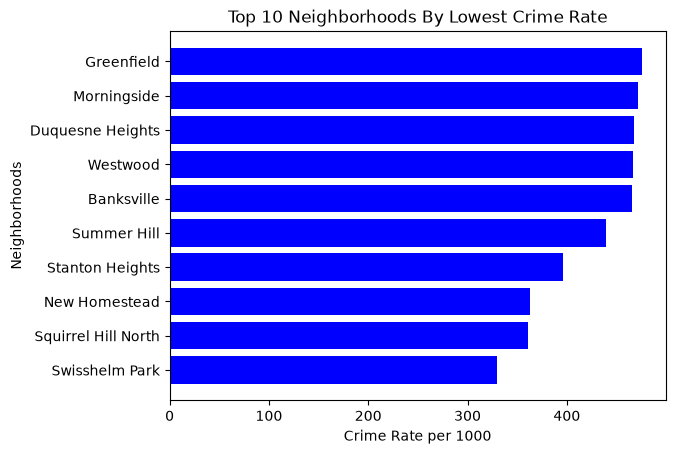

In [13]:
values= []
topTenNeighborhoods=list(crimePerNeighborhood)[:10]

for neighborhood in topTenNeighborhoods:
    values.append(crimePerNeighborhood[neighborhood])
neighborhoods= list(topTenNeighborhoods)

plt.barh(neighborhoods,values, color='blue')
plt.xlabel('Crime Rate per 1000')
plt.ylabel('Neighborhoods')
plt.title('Top 10 Neighborhoods By Lowest Crime Rate')
plt.show()

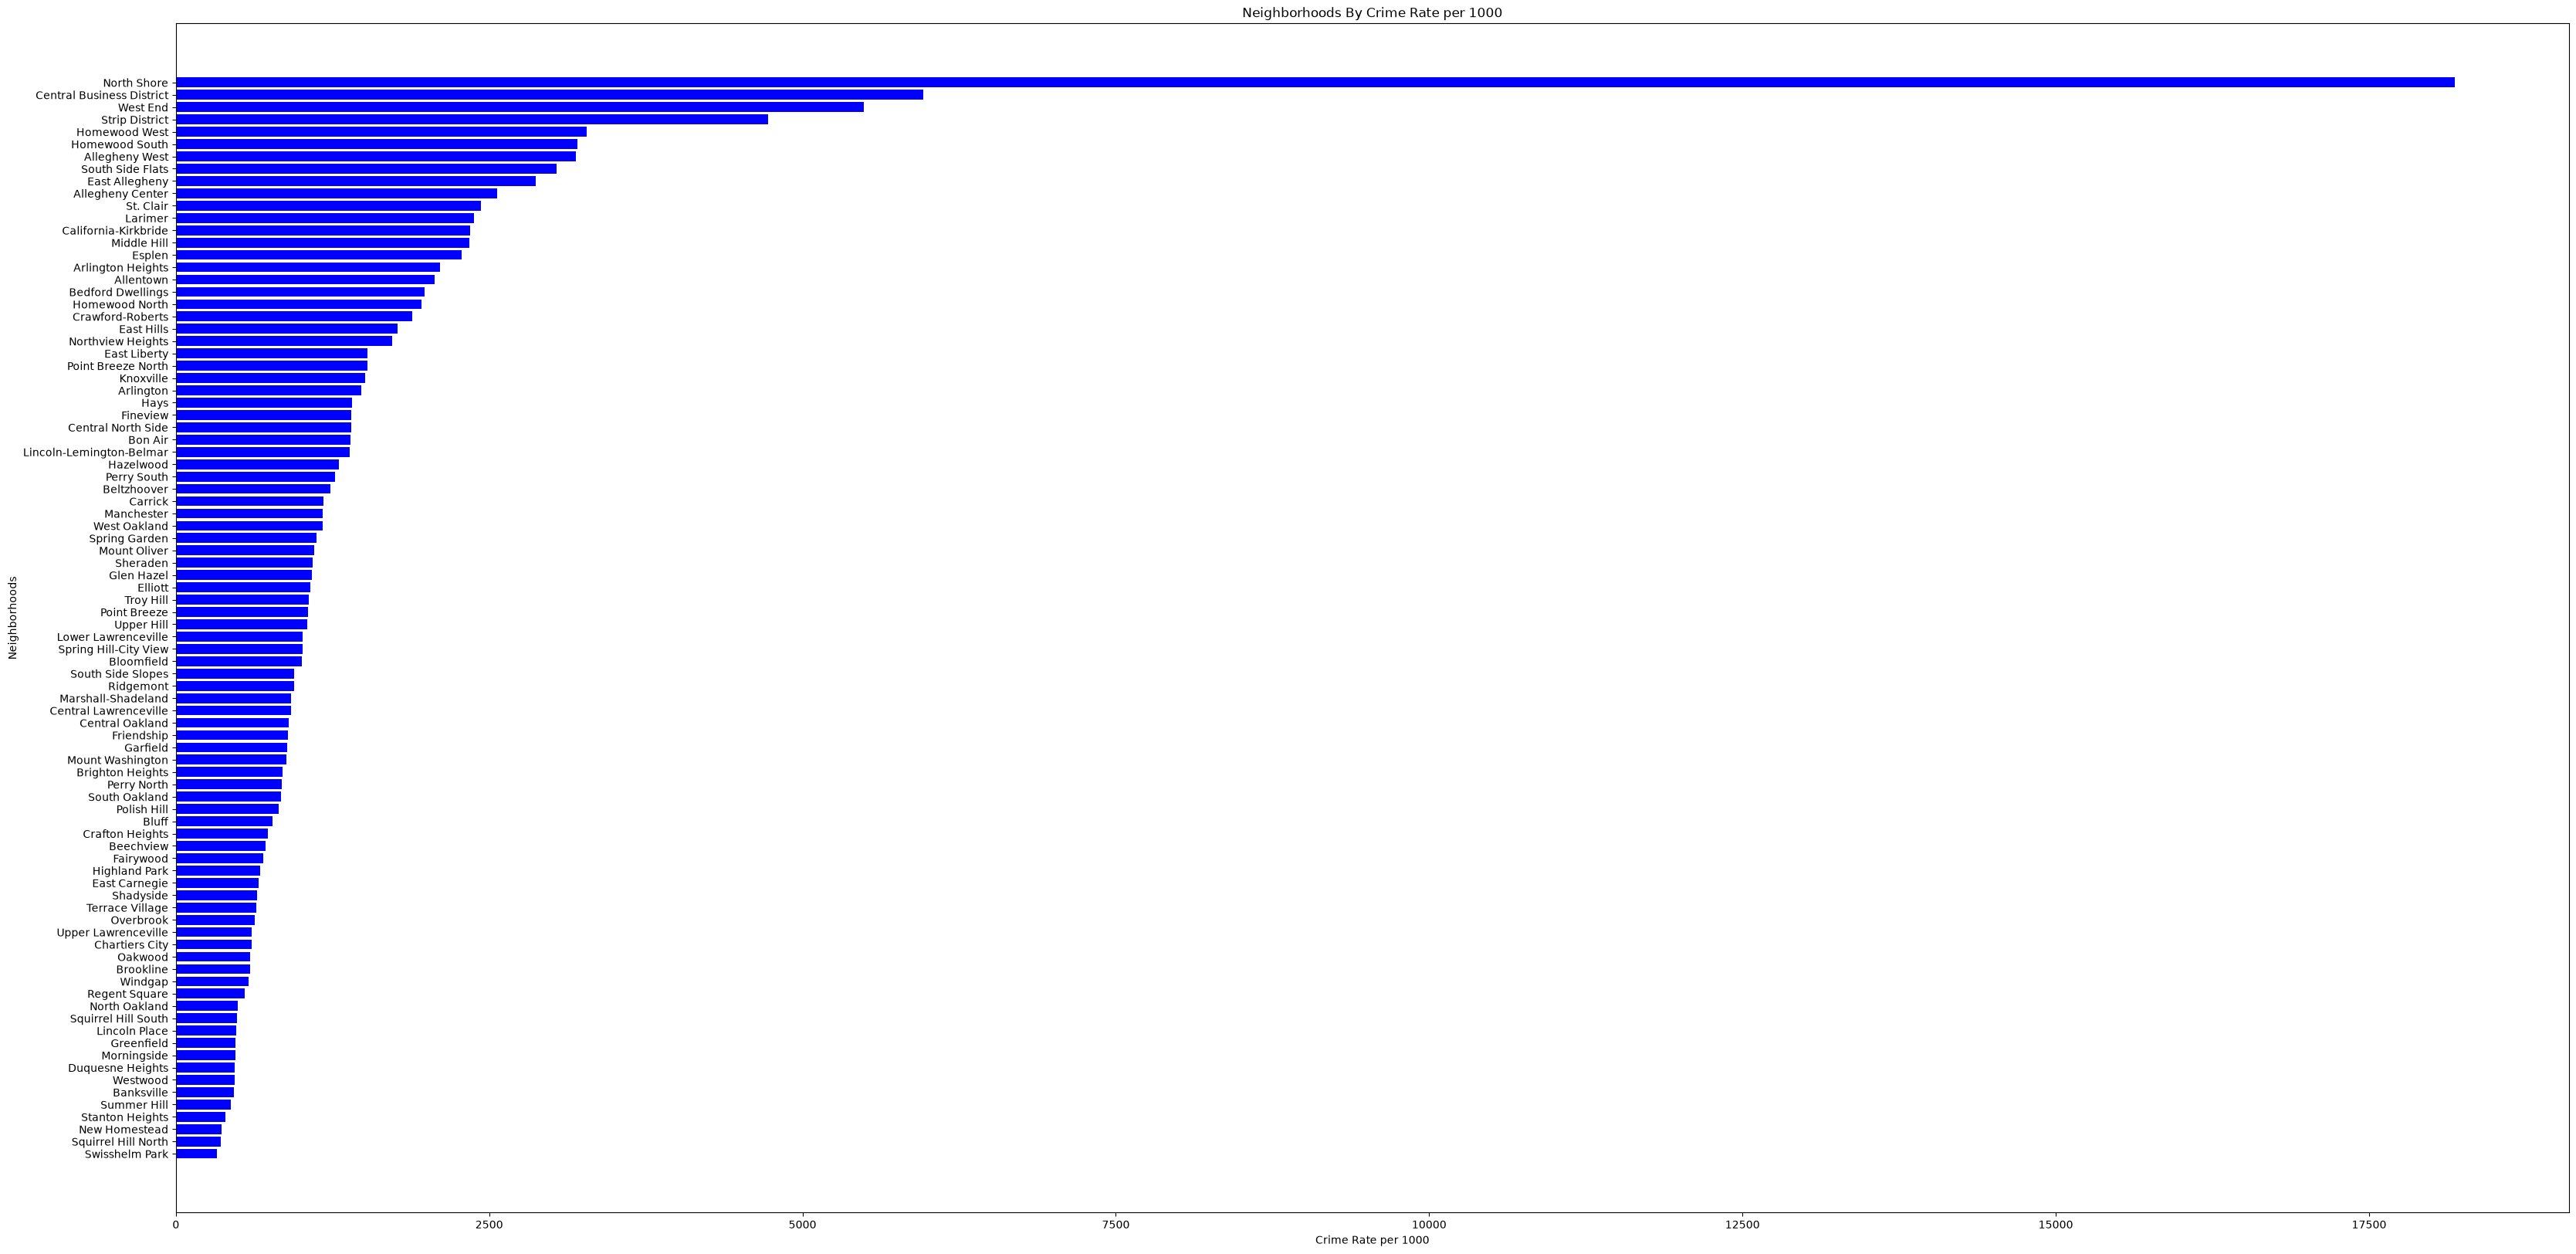

In [14]:
values= []
neighborhoods=list(crimePerNeighborhood)[:len(crimePerNeighborhood)-2]
#excludes highest two crime rates because they have such a low population it makes their crime rate very high and makes the graph unreadable

for neighborhood in neighborhoods:
    values.append(crimePerNeighborhood[neighborhood])

plt.figure(figsize=(40,20))
plt.barh(neighborhoods,values, color='blue')
plt.xlabel('Crime Rate per 1000')
plt.ylabel('Neighborhoods')
plt.title('Neighborhoods By Crime Rate per 1000')
plt.show()

In [15]:
neighborhoods=list(crimePerNeighborhood)
values= []
for neighborhood in neighborhoods:
    values.append(crimePerNeighborhood[neighborhood])


pd.DataFrame({'Neighborhood' : neighborhoods, 'Crime Rate per 1000' : values}).to_csv("CrimeRate_Neighborhood.csv", index=False)